# Crop coefficient $K_c$ of plot AF (FAO-56)

Input: `ET0_results_hourly.csv`, saved by the ET0 notebook. Only the AF weather (`T_hr`, `ea`, `u2`) is used.

1. Imports and the FAO-56 functions needed here
2. Settings and species
3. Mean climate of the plot
4. Equations
5. $K_c$ per species, per zone and for the whole plot, per stage and **now** (current stage of each species)
6. Sensitivity of the current plot $K_c$ to the leaf resistance $r_l$ of the trees

## 1. Imports and functions (copied from the ET0 notebook)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def calc_P(z):
    '''Atmospheric pressure P [kPa] from elevation z [m] (Eq. 7).'''
    return 101.3 * ((293 - 0.0065 * z) / 293) ** 5.26


def calc_gamma(P):
    '''Psychrometric constant gamma [kPa/degC] (Eq. 8).'''
    return 0.665e-3 * P


def calc_e0(T):
    '''Saturation vapour pressure e0(T) [kPa] (Eq. 11).'''
    return 0.6108 * np.exp(17.27 * T / (T + 237.3))


def calc_delta(T_hr):
    '''Slope of the saturation vapour pressure curve delta [kPa/degC] (Eq. 13).'''
    return 4098 * calc_e0(T_hr) / (T_hr + 237.3) ** 2

## 2. Settings and species - the only cell you need to edit

In [3]:
DATA_FILE = 'ET0_results_hourly.csv'   # output of the ET0 notebook
PLOT      = 'AF'
phi_deg   = 15.37                      # latitude [deg N]
z         = 1420                       # elevation of the plot [m]  <- verify for AF

F_crops, F_contour = 0.50, 0.50       

Kc_ini_fig29 = 0.90                    # Kc_ini from FAO-56 Fig. 29 (wetting every 1-2 days, your ET0)  <- read off
USE_FIG29_FOR_CROPS = True             # True: Table 12 species use Kc_ini_fig29 | False: keep Table 12 Kc_ini

# Lower limit of the tree Kc in Eq. 98.
#   Kc_ini_fig29 (0.90): soil under the hedge is wet every 1-2 days -> trees can never go below 0.90
#   ~0.15-0.20         : bare-soil Kc_min (FAO-56 Eq. 98) -> tree parameters (fc, h, rl) actually matter
KC_MIN_TREE = 0.15                     # bare-soil Kc_min, FAO-56 Eq. 98 (trees only)

# Table 12 values (or proxy row), height h [m], and f = share of the crop zone [-]
# stage = growth stage of the species NOW (measurement period): 'ini', 'dev', 'mid', 'late' or 'end'
#   ('end' also for species harvested in the last weeks whose residues/regrowth still cover the soil)
# f is optional: species without f get equal weights. If you give f, give it to all and make them sum to 1.
CROPS = {
    'Xanthosoma sagittifolium':  dict(Kc_ini=0.50, Kc_mid=1.15, Kc_end=0.65, h=1.7, stage='mid',f=0.14),   # proxy: Sweet potato
    'Crotalaria longirostrata':  dict(Kc_ini=0.80, Kc_mid=1.15, Kc_end=0.85, h=1.8, stage='mid',f=0.14),   # flowering, green leaves
    'Manihot esculenta':         dict(Kc_ini=0.30, Kc_mid=0.80, Kc_end=0.30, h=2.5, stage='mid',f=0.15),   # Cassava year 1
    'Cucurbita moschata':        dict(Kc_ini=0.50, Kc_mid=1.00, Kc_end=0.80, h=0.5, stage='mid',f=0.15),   # Pumpkin; fruits growing + flowers
    'Solanum nigrum':            dict(Kc_ini=0.70, Kc_mid=1.05, Kc_end=0.95, h=1.0, stage='mid', f=0.05),   # proxy: Small vegetables; small green fruits
    'Tinantia erecta':           dict(Kc_ini=0.70, Kc_mid=1.05, Kc_end=0.95, h=0.7, stage='late', f=0.05),  # proxy: Small vegetables; rainy-season annual  <- check
    'Solanum quitoense':         dict(Kc_ini=0.60, Kc_mid=1.15, Kc_end=0.80, h=2.5, stage='mid', f=0.05),   # proxy: Solanum family
    'Vaccinium spp.':            dict(Kc_ini=0.30, Kc_mid=1.05, Kc_end=0.50, h=2.0, stage='mid', f=0.02),   # Berries (bushes)
    'Cajanus cajan':             dict(Kc_ini=0.40, Kc_mid=1.05, Kc_end=0.35, h=1.1, stage='mid', f=0.15),   # proxy: Green gram and cowpeas
    'Chenopodium nuttalliae':    dict(Kc_ini=0.70, Kc_mid=1.05, Kc_end=0.95, h=1.0, stage='mid', f=0.05),   # proxy: Small vegetables; blooming
    'Persea schiedeana':         dict(Kc_ini=0.60, Kc_mid=0.85, Kc_end=0.75, h=1.7, stage='mid', f=0.02),   # proxy: Avocado, no ground cover
    'Amaranthus hybridus':       dict(Kc_ini=0.70, Kc_mid=1.05, Kc_end=0.95, h=1.7, stage='late', f=0.02),  # proxy: Small vegetables; seeding  <- check
    'Camellia sinensis':         dict(Kc_ini=0.95, Kc_mid=1.00, Kc_end=1.00, h=0.7, stage='mid', f=0.01),   # Tea, non-shaded
}
SHRUBS = {}   # contour species with a Table 12 row (none now)

# Trees in a continuous hedge (FAO-56 Ch. 9, Box 18) - all values are placeholders:
#   fc       = fraction of the ground under the crowns [-] (1 = continuous canopy, gaps between leaves don't count)
#   h        = tree height [m]
#   h_canopy = height of the leafy part only [m]
#   width    = hedge (crown) width [m]
#   G_row    = hedge direction: 0 = east-west, np.pi/2 = north-south
#   rl       = mean leaf resistance [s/m], central value; rl_lo / rl_hi = range for the sensitivity analysis
#              (100 = FAO-56 value for crops; derived from max. leaf conductance per vegetation type, see section 6)
#   f        = share of the contour zone taken by this species [-] (optional, see above)
# rl from Kelliher et al. (1995) Table 1, g_smax mean +- SD per vegetation type, scaled to the FAO-56 crop value:
#   rl = 100 * g_crop / g_smax, with g_crop = 11.6 mm/s (agricultural crops, Kelliher et al. 1995)
#   rl_lo / rl_hi from g_smax + SD / g_smax - SD
TREES = {   #                                                                       conifer forest: 5.7 +- 2.4 mm/s
    'Cupressus lusitanica':    dict(fc=1.0, h=22.5, h_canopy=18.5, width=3.8, G_row=np.radians(32), rl=204, rl_lo=143, rl_hi=352),
    'Pinus spp.':              dict(fc=1.0, h=22.5, h_canopy=12.5, width=7.8, G_row=np.radians(32), rl=204, rl_lo=143, rl_hi=352),
    #                                                                                  evergreen broadleaf (eucalypt forest): 5.3 +- 3.0 mm/s
    'Quercus spp.':            dict(fc=1.0, h=10.0, h_canopy=8, width=5.4, G_row=np.radians(32), rl=219, rl_lo=140, rl_hi=504),
    #                                                                                  temperate deciduous forest: 4.6 +- 1.7 mm/s
    'Liquidambar styraciflua': dict(fc=1.0, h=22.5, h_canopy=21, width=4.0, G_row=np.radians(32), rl=252, rl_lo=184, rl_hi=400),
    #                                                                                  tropical rainforest: 6.1 +- 3.2 mm/s
}

## 3. Mean climate of the plot

$u_2$, $RH_{min}$ (daily minimum of $RH = 100\,e_a/e^\circ(T_{hr})$, Eq. 10, averaged over the days), mean $T$, and the middle day $J$ of the record.

In [4]:
d = pd.read_csv(DATA_FILE, parse_dates=['Timestamp'])
assert (d['plot'] == PLOT).any(), f"No rows for plot {PLOT!r}; plots in file: {d['plot'].unique()}"
d = d[d['plot'] == PLOT].set_index('Timestamp').sort_index()

u2    = d['u2'].mean()                                                                       # [m/s]
RHmin = (100 * d['ea'] / calc_e0(d['T_hr'])).clip(upper=100).resample('D').min().mean()      # [%]
T     = d['T_hr'].mean()                                                                     # [degC]
J     = int(d.index.dayofyear.to_series().median())                                          # [-]
print(f'Plot {PLOT}: u2 = {u2:.2f} m/s, RHmin = {RHmin:.0f} %, T = {T:.1f} degC, J = {J}')
if u2 < 1:
    print('Note: u2 < 1 m/s -> the climate correction uses u2 = 1 m/s (FAO-56 validity range).')

Plot AF: u2 = 0.36 m/s, RHmin = 79 %, T = 19.4 degC, J = 282
Note: u2 < 1 m/s -> the climate correction uses u2 = 1 m/s (FAO-56 validity range).


## 4. Equations

- Table 12 species: $K_{c,mid}$ and $K_{c,end}$ corrected for climate (Eq. 62, 65, with $u_2$ clipped to 1-6 m/s and $RH_{min}$ to 20-80 %); $K_{c,ini}$ from Fig. 29.
- Trees (Ch. 9, single $K_c$): $K_c = K_{c,min} + (F_r\,K_{cb,full} - K_{c,min})\,\min(1,\ 2f_c,\ f_{c,eff}^{1/(1+h)})$, with $K_{c,min}$ as lower limit; evergreen so ini = mid = end. The climate term uses the same clipping as Eq. 62. Note: the trees (22.5 m) are taller than the heights these equations were derived for.
- Mixing within a zone: $K_c = \sum f_i h_i K_{c,i} / \sum f_i h_i$ (FAO-56 Ch. 9).

In [5]:
def climate_term(h):
    '''Climate correction term of Eq. 62 / 65 / 100, with FAO-56 validity limits on u2 and RHmin.'''
    return (0.04 * (np.clip(u2, 1, 6) - 2) - 0.004 * (np.clip(RHmin, 20, 80) - 45)) * (h / 3) ** 0.3


def Kc_table12(s):
    '''Kc_ini, Kc_mid, Kc_end of a species in Table 12.'''
    Kc_ini = Kc_ini_fig29 if USE_FIG29_FOR_CROPS else s['Kc_ini']
    Kc_mid = s['Kc_mid'] + climate_term(s['h'])                                              # Eq. 62
    Kc_end = s['Kc_end'] + climate_term(s['h']) if s['Kc_end'] >= 0.45 else s['Kc_end']      # Eq. 65
    Kc_now = {'ini': Kc_ini, 'dev': (Kc_ini + Kc_mid) / 2, 'mid': Kc_mid,
              'late': (Kc_mid + Kc_end) / 2, 'end': Kc_end}[s.get('stage', 'mid')]           # current stage
    return Kc_ini, Kc_mid, Kc_end, Kc_now


def Kc_tree(s):
    '''Kc of an evergreen hedge, FAO-56 Ch. 9 (Eq. 98, lower limit KC_MIN_TREE). Returns ini = mid = end = now (evergreen).'''
    phi = np.radians(phi_deg)
    dec = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)                          # Eq. 24
    eta = np.arcsin(np.sin(phi) * np.sin(dec) + np.cos(phi) * np.cos(dec))     # Box 18, sun at solar noon
    HWR = s['h_canopy'] / s['width'] * np.cos(s['G_row'])                     # Box 18
    fc_eff = min(s['fc'] * (1 + HWR / np.tan(eta)), 1.0)                      # Box 18, rows
    h = s['h']

    Kcb_h    = min(1.0 + 0.1 * h, 1.20)                                       # Eq. 101
    Kcb_full = Kcb_h + climate_term(h)                                        # Eq. 100
    delta, gamma = calc_delta(T), calc_gamma(calc_P(z))
    Fr = (delta + gamma * (1 + 0.34 * u2)) / (delta + gamma * (1 + 0.34 * u2 * s['rl'] / 100))   # Eq. 102
    Kc_full = Fr * Kcb_full

    Kd = min(1.0, 2 * s['fc'], fc_eff ** (1 / (1 + h)))
    Kc = max(KC_MIN_TREE + (Kc_full - KC_MIN_TREE) * Kd, KC_MIN_TREE)        # Eq. 98
    return Kc, Kc, Kc, Kc


def Kc_zone(Kc, h, f):
    '''Kc of one zone: sum(f_i h_i Kc_i) / sum(f_i h_i).'''
    return (f * h * Kc).sum() / (f * h).sum()

## 5. $K_c$ per species, per zone and for the whole plot

Within each zone: area- and height-weighted (initial stage: area only, since crop cover is negligible).
$K_{c,now}$ uses the `stage` of each species in the measurement period ('dev' and 'late' = mean of the two neighbouring values, a simplification of the linear Eq. 66); this is the value to use for the current ET.
Between zones (only for the current situation): $K_{c,plot,now} = F_{crops}\,K_{c,crops,now} + F_{contour}\,K_{c,contour,now}$.

In [6]:
cols = ['Kc_ini', 'Kc_mid', 'Kc_end', 'Kc_now']

h_crops     = pd.Series({n: s['h'] for n, s in CROPS.items()})
h_crops_ini = pd.Series(1.0, index=h_crops.index)          # initial stage: area weights only
h_contour   = pd.Series({n: s['h'] for n, s in {**SHRUBS, **TREES}.items()})

f_crops   = pd.Series({n: s.get('f', 1.0) for n, s in CROPS.items()})
f_contour = pd.Series({n: s.get('f', 1.0) for n, s in {**SHRUBS, **TREES}.items()})


def compute_Kc(trees):
    '''Kc per species and per zone for a given TREES dict.'''
    Kc_crops   = pd.DataFrame({n: Kc_table12(s) for n, s in CROPS.items()}, index=cols).T
    Kc_contour = pd.DataFrame({**{n: Kc_table12(s) for n, s in SHRUBS.items()},
                               **{n: Kc_tree(s)    for n, s in trees.items()}}, index=cols).T
    Kc_zones = pd.DataFrame({
        'crops':   {'Kc_ini': Kc_zone(Kc_crops['Kc_ini'], h_crops_ini, f_crops),
                    'Kc_mid': Kc_zone(Kc_crops['Kc_mid'], h_crops, f_crops),
                    'Kc_end': Kc_zone(Kc_crops['Kc_end'], h_crops, f_crops),
                    'Kc_now': Kc_zone(Kc_crops['Kc_now'], h_crops, f_crops)},
        'contour': {c: Kc_zone(Kc_contour[c], h_contour, f_contour) for c in cols},
    })
    return Kc_crops, Kc_contour, Kc_zones


def Kc_plot_now(trees):
    '''Kc of the whole plot now (current stage of each species) for a given TREES dict.'''
    _, _, z = compute_Kc(trees)
    return F_crops * z.loc['Kc_now', 'crops'] + F_contour * z.loc['Kc_now', 'contour']


Kc_crops, Kc_contour, Kc_zones = compute_Kc(TREES)

stage = pd.Series({**{n: s.get('stage', 'mid') for n, s in CROPS.items()}, **{n: 'evergreen' for n in TREES}}, name='stage_now')
display(pd.concat([Kc_crops, Kc_contour]).round(2).join(stage))

Kc_AF_now = Kc_plot_now(TREES)
print(f'Kc of plot {PLOT} now = {F_crops} x {Kc_zones.loc["Kc_now", "crops"]:.3f} (crops) ')
print(Kc_trees)


,Kc_ini,Kc_mid,Kc_end,Kc_now,stage_now
Xanthosoma sagittifolium,0.90,1.00,0.50,1.00,mid
Crotalaria longirostrata,0.90,1.00,0.70,1.00,mid
Manihot esculenta,0.90,0.63,0.30,0.63,mid
Cucurbita moschata,0.90,0.90,0.70,0.90,mid
Solanum nigrum,0.90,0.92,0.82,0.92,mid
Tinantia erecta,0.90,0.94,0.84,0.89,late
Solanum quitoense,0.90,0.98,0.63,0.98,mid
Vaccinium spp.,0.90,0.89,0.34,0.89,mid
Cajanus cajan,0.90,0.92,0.35,0.92,mid
Chenopodium nuttalliae,0.90,0.92,0.82,0.92,mid


Kc of plot AF now = 0.5 x 0.870 (crops) 


NameError: name 'Kc_trees' is not defined

In [ ]:
# Crop Kc with every species one growth stage earlier / later (sensitivity to the stage assignment)
STAGES = ['ini', 'dev', 'mid', 'late', 'end']


def Kc_AF_shifted(shift):
    '''Plot Kc with every crop moved `shift` stages (-1 = earlier, +1 = later); trees unchanged.'''
    crops_s = {n: {**s, 'stage': STAGES[min(max(STAGES.index(s.get('stage', 'mid')) + shift, 0), 4)]}
               for n, s in CROPS.items()}
    Kc_s = pd.DataFrame({n: Kc_table12(s) for n, s in crops_s.items()}, index=cols).T
    Kc_crops_s = Kc_zone(Kc_s['Kc_now'], h_crops, f_crops)
    return Kc_crops_s, F_crops * Kc_crops_s + F_contour * Kc_zones.loc['Kc_now', 'contour']


Kc_crops_earlier, Kc_AF_earlier = Kc_AF_shifted(-1)
Kc_crops_later,   Kc_AF_later   = Kc_AF_shifted(+1)
print(f'Crop zone Kc: earlier {Kc_crops_earlier:.3f} | central {Kc_zones.loc["Kc_now", "crops"]:.3f} | later {Kc_crops_later:.3f}')
print(f'Plot Kc AF:   earlier {Kc_AF_earlier:.3f} | central {Kc_AF_now:.3f} | later {Kc_AF_later:.3f}')

Crop zone Kc: earlier 0.887 | central 0.870 | later 0.697
Plot Kc AF:   earlier 0.870 | central 0.862 | later 0.775


## 6. Sensitivity of $K_{c,plot,now}$ to the leaf resistance $r_l$ of the trees

One-at-a-time: each tree species is set to its low and high $r_l$ (`rl_lo`, `rl_hi`) while the others keep their central value; the last bar sets all trees low / high together.

**Values.** $r_l$ is taken proportional to $1/g_{s,max}$ and scaled so that crops give the FAO-56 value of 100 s/m:
$r_l = 100 \cdot g_{crop} / g_{s,max}$, with $g_{crop}$ = 11.6 mm/s (agricultural crops; Kelliher et al., 1995).
$g_{s,max}$ per vegetation type (mean ± SD, Kelliher et al., 1995, Table 1; consistent with Schulze et al., 1994, Table 1):

| Species | Vegetation type used | $g_{s,max}$ [mm/s] | $r_l$ (low–high) [s/m] |
|---|---|---|---|
| *Cupressus*, *Pinus* | conifer forest | 5.7 ± 2.4 | 204 (143–352) |
| *Quercus* | eucalypt forest (evergreen broadleaf) | 5.3 ± 3.0 | 219 (140–504) |
| *Liquidambar* | temperate deciduous forest | 4.6 ± 1.7 | 252 (184–400) |
| *Ochroma* | tropical rainforest | 6.1 ± 3.2 | 190 (125–400) |

Kelliher et al. (1995) find no systematic difference in $g_{s,max}$ between woody vegetation types (≈ 6 mm/s for natural vegetation vs ≈ 12 mm/s for crops), so the central values are similar and the ranges (± 1 SD, i.e. species-to-species variability) matter more.

,Kc (rl low),Kc (rl high),range
Cupressus lusitanica (143-352 s/m),0.864,0.856,0.008
Pinus spp. (143-352 s/m),0.864,0.856,0.008
Quercus spp. (140-504 s/m),0.863,0.857,0.007
Liquidambar styraciflua (184-400 s/m),0.864,0.856,0.008
All trees together,0.871,0.840,0.031


,Kc crops,Kc trees (contour),Kc plot now,change vs central
min rl,0.87,0.872,0.871,0.009
central rl,0.87,0.853,0.862,0.000
max rl,0.87,0.809,0.840,-0.022


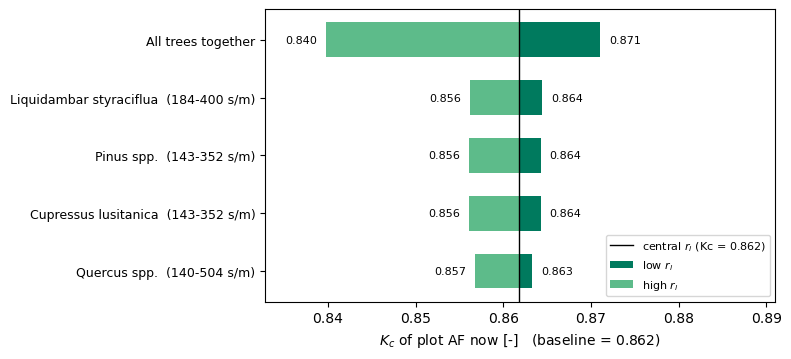

In [ ]:
base = Kc_plot_now(TREES)
rows = {}
for n, s in TREES.items():
    lo = Kc_plot_now({**TREES, n: {**s, 'rl': s['rl_lo']}})
    hi = Kc_plot_now({**TREES, n: {**s, 'rl': s['rl_hi']}})
    rows[f"{n}  ({s['rl_lo']}-{s['rl_hi']} s/m)"] = (lo, hi)
rows['All trees together'] = (Kc_plot_now({n: {**s, 'rl': s['rl_lo']} for n, s in TREES.items()}),
                              Kc_plot_now({n: {**s, 'rl': s['rl_hi']} for n, s in TREES.items()}))

sens = pd.DataFrame(rows, index=['Kc (rl low)', 'Kc (rl high)']).T
sens['range'] = (sens['Kc (rl low)'] - sens['Kc (rl high)']).abs()
display(sens.round(3))

# Kc of the trees (contour zone) and of the plot: all trees at min / central / max rl
cases = {'min rl': 'rl_lo', 'central rl': 'rl', 'max rl': 'rl_hi'}
rows_c = {}
for label, key in cases.items():
    trees_c = {n: {**s, 'rl': s[key]} for n, s in TREES.items()}
    _, _, zones_c = compute_Kc(trees_c)
    rows_c[label] = {'Kc crops':           zones_c.loc['Kc_now', 'crops'],
                     'Kc trees (contour)': zones_c.loc['Kc_now', 'contour'],
                     'Kc plot now':        Kc_plot_now(trees_c)}
trees_tab = pd.DataFrame(rows_c).T
trees_tab['change vs central'] = trees_tab['Kc plot now'] - trees_tab.loc['central rl', 'Kc plot now']
display(trees_tab.round(3))

# tornado chart (all-trees bar at the top)
order = list(sens.index[:-1][np.argsort(sens['range'].values[:-1])]) + ['All trees together']
fig, ax = plt.subplots(figsize=(8, 0.5 * len(order) + 1.2))
C_LOW, C_HIGH = '#007A5E', '#5DBB8A'   # low r_l (main), high r_l (secondary)

for i, name in enumerate(order):
    lo, hi = sens.loc[name, ['Kc (rl low)', 'Kc (rl high)']]
    ax.barh(i, lo - base, left=base, color=C_LOW,  height=0.6, label='low $r_l$'  if i == 0 else None)
    ax.barh(i, hi - base, left=base, color=C_HIGH, height=0.6, label='high $r_l$' if i == 0 else None)
    for v in (lo, hi):   # label at the end of each bar, on its own side
        right = v >= base
        ax.text(v + (0.001 if right else -0.001), i, f'{v:.3f}', va='center',
                ha='left' if right else 'right', fontsize=8)
ax.axvline(base, color='black', lw=1, label=f'central $r_l$ (Kc = {base:.3f})')
ax.set_yticks(range(len(order)), labels=order, fontsize=9)
ax.set_xlabel(f'$K_{{c}}$ of plot {PLOT} now [-]   (baseline = {base:.3f})')
ax.legend(loc='lower right', fontsize=8)
xmin, xmax = sens[['Kc (rl low)', 'Kc (rl high)']].values.min(), sens[['Kc (rl low)', 'Kc (rl high)']].values.max()
ax.set_xlim(xmin - 0.007, xmax + 0.02)
plt.tight_layout()
fig.savefig(f'tornado_rl_{PLOT}.png', dpi=300, bbox_inches='tight')
plt.show()

### Kc of each tree species over its own $r_l$ range

Same ranges as above, but showing the $K_c$ of the tree itself (low / central / high $r_l$); central column outlined.

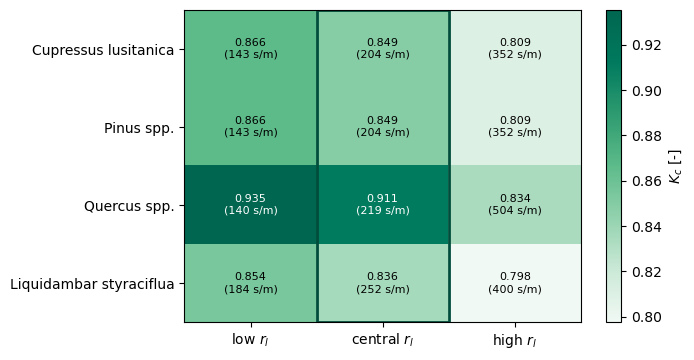

In [ ]:
from matplotlib.patches import Rectangle

cases = {'low': 'rl_lo', 'central': 'rl', 'high': 'rl_hi'}
kc_tree_tab = pd.DataFrame({c: {n: Kc_tree({**s, 'rl': s[k]})[0] for n, s in TREES.items()} for c, k in cases.items()})
rl_tab      = pd.DataFrame({c: {n: s[k] for n, s in TREES.items()} for c, k in cases.items()})

fig, ax = plt.subplots(figsize=(7, 0.55 * len(TREES) + 1.5))

from matplotlib.colors import LinearSegmentedColormap
GREENS = LinearSegmentedColormap.from_list('greens_AF', ['#F1F9F4', '#CBE9D7', '#93D2AE', '#5DBB8A', '#2E9B70', '#007A5E', '#00664F'])
im = ax.imshow(kc_tree_tab.values, cmap=GREENS, aspect='auto')

ax.set_xticks(range(3), labels=[r'low $r_l$', r'central $r_l$', r'high $r_l$'])
ax.set_yticks(range(len(TREES)), labels=kc_tree_tab.index)
vmin, vmax = kc_tree_tab.values.min(), kc_tree_tab.values.max()
for i in range(kc_tree_tab.shape[0]):
    for j in range(3):
        v = kc_tree_tab.iat[i, j]
        dark = v > vmin + 0.6 * (vmax - vmin)
        ax.text(j, i, f'{v:.3f}\n({rl_tab.iat[i, j]:.0f} s/m)', ha='center', va='center',
                fontsize=8, color='white' if dark else 'black')
ax.add_patch(Rectangle((0.5, -0.5), 1, len(TREES), fill=False, ec='#004d3b', lw=2))
fig.colorbar(im, ax=ax, label=r'$K_c$ [-]')
plt.tight_layout()
fig.savefig(f'heatmap_tree_Kc_rl_{PLOT}.png', dpi=300, bbox_inches='tight')
plt.show()

### Save

In [ ]:
Kc_zones.to_csv(f'Kc_{PLOT}_zones.csv')                                   # per zone and stage
pd.Series({'Kc_now': Kc_AF_now}, name=PLOT).to_csv(f'Kc_{PLOT}.csv')     # the value for the ET calculation
print(f"Saved Kc_{PLOT}.csv (Kc now = {Kc_AF_now:.3f}) and Kc_{PLOT}_zones.csv")

Saved Kc_AF.csv (Kc now = 0.862) and Kc_AF_zones.csv


,Kc (low value),Kc (high value),range
Crop growth stage (earlier / later),0.870,0.775,0.095
Tree leaf resistance $r_l$ (all trees),0.871,0.840,0.031
Crop height (x0.8 / x1.2),0.867,0.858,0.009
Tree height (x0.8 / x1.2),0.871,0.853,0.018
Crop-zone share $F_{crops}$ (0.45-0.55),0.861,0.863,0.002
All together (envelope),0.736,0.892,0.155


Kc AF = 0.862 (envelope 0.736-0.892)


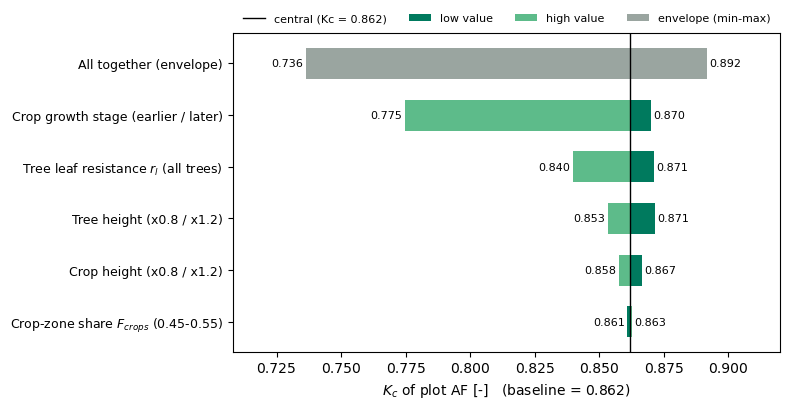

In [ ]:
# ---- Sensitivity of Kc of AF to the crop and tree parameters (same layout as the CF chart) ----
# One-at-a-time: each parameter is set to its low and high value, everything else at its central value.
# Last bar = envelope (min-max) over all combinations of low / central / high of all parameters.
import itertools

H_FACTOR = (0.8, 1.2)       # heights x 0.8 / x 1.2 (no measured range)          <- set your own range
F_RANGE  = (0.45, 0.55)     # area share of the crop zone F_crops                 <- set your own range
STAGES   = ['ini', 'dev', 'mid', 'late', 'end']


def Kc_AF_case(crops=CROPS, trees=TREES, F=F_crops):
    '''Kc of the whole AF plot now for given crop and tree dicts and crop-zone share F.'''
    Kc_c = pd.Series({n: Kc_table12(s)[3] for n, s in crops.items()})
    h_c  = pd.Series({n: s['h'] for n, s in crops.items()})
    f_c  = pd.Series({n: s.get('f', 1.0) for n, s in crops.items()})
    cont = {**SHRUBS, **trees}
    Kc_t = pd.Series({**{n: Kc_table12(s)[3] for n, s in SHRUBS.items()},
                      **{n: Kc_tree(s)[0] for n, s in trees.items()}})
    h_t  = pd.Series({n: s['h'] for n, s in cont.items()})
    f_t  = pd.Series({n: s.get('f', 1.0) for n, s in cont.items()})
    return F * Kc_zone(Kc_c, h_c, f_c) + (1 - F) * Kc_zone(Kc_t, h_t, f_t)


def crops_stage(shift):
    '''Every crop moved `shift` growth stages (-1 = earlier, +1 = later).'''
    return {n: {**s, 'stage': STAGES[min(max(STAGES.index(s.get('stage', 'mid')) + shift, 0), 4)]}
            for n, s in CROPS.items()}


def crops_h(k):
    return {n: {**s, 'h': s['h'] * k} for n, s in CROPS.items()}


def trees_h(k):
    return {n: {**s, 'h': s['h'] * k, 'h_canopy': s['h_canopy'] * k} for n, s in TREES.items()}


def trees_rl(key):
    return {n: {**s, 'rl': s[key]} for n, s in TREES.items()}


# each parameter: (label, {level: kwargs for Kc_AF_case}) with levels 'lo', 'c', 'hi'
PARAMS_AF = [
    ('Crop growth stage (earlier / later)',
     {'lo': dict(crops=crops_stage(-1)), 'c': {}, 'hi': dict(crops=crops_stage(+1))}),
    ('Tree leaf resistance $r_l$ (all trees)',
     {'lo': dict(trees=trees_rl('rl_lo')), 'c': {}, 'hi': dict(trees=trees_rl('rl_hi'))}),
    (f'Crop height (x{H_FACTOR[0]} / x{H_FACTOR[1]})',
     {'lo': dict(crops=crops_h(H_FACTOR[0])), 'c': {}, 'hi': dict(crops=crops_h(H_FACTOR[1]))}),
    (f'Tree height (x{H_FACTOR[0]} / x{H_FACTOR[1]})',
     {'lo': dict(trees=trees_h(H_FACTOR[0])), 'c': {}, 'hi': dict(trees=trees_h(H_FACTOR[1]))}),
    (f'Crop-zone share $F_{{crops}}$ ({F_RANGE[0]}-{F_RANGE[1]})',
     {'lo': dict(F=F_RANGE[0]), 'c': {}, 'hi': dict(F=F_RANGE[1])}),
]

base_AF = Kc_AF_case()
assert abs(base_AF - Kc_AF_now) < 1e-9, 'Central case differs from Kc_AF_now'

rows = {lab: (Kc_AF_case(**lv['lo']), Kc_AF_case(**lv['hi'])) for lab, lv in PARAMS_AF}


def combo(levels):
    '''Kc for one combination of levels; crop stage and crop height act on the same dict.'''
    stage, rl, hc, ht, F = levels
    crops = crops_stage({'lo': -1, 'c': 0, 'hi': 1}[stage])
    crops = {n: {**s, 'h': s['h'] * {'lo': H_FACTOR[0], 'c': 1, 'hi': H_FACTOR[1]}[hc]} for n, s in crops.items()}
    trees = trees_rl({'lo': 'rl_lo', 'c': 'rl', 'hi': 'rl_hi'}[rl])
    k = {'lo': H_FACTOR[0], 'c': 1, 'hi': H_FACTOR[1]}[ht]
    trees = {n: {**s, 'h': s['h'] * k, 'h_canopy': s['h_canopy'] * k} for n, s in trees.items()}
    return Kc_AF_case(crops=crops, trees=trees, F={'lo': F_RANGE[0], 'c': F_crops, 'hi': F_RANGE[1]}[F])


all_AF = [combo(ls) for ls in itertools.product(['lo', 'c', 'hi'], repeat=len(PARAMS_AF))]
ENV = 'All together (envelope)'
rows[ENV] = (min(all_AF), max(all_AF))

sens_KcAF = pd.DataFrame(rows, index=['Kc (low value)', 'Kc (high value)']).T
sens_KcAF['range'] = (sens_KcAF['Kc (low value)'] - sens_KcAF['Kc (high value)']).abs()
display(sens_KcAF.round(3))
print(f'Kc AF = {base_AF:.3f} (envelope {min(all_AF):.3f}-{max(all_AF):.3f})')

# tornado chart (envelope bar at the top)
order = list(sens_KcAF.index[:-1][np.argsort(sens_KcAF['range'].values[:-1])]) + [ENV]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(order) + 1.2))
C_LOW, C_HIGH, C_ENV = '#007A5E', '#5DBB8A', '#9AA5A0'
for i, name in enumerate(order):
    lo, hi = sens_KcAF.loc[name, ['Kc (low value)', 'Kc (high value)']]
    if name == ENV:
        ax.barh(i, hi - lo, left=lo, color=C_ENV, height=0.6, label='envelope (min-max)')
    else:
        ax.barh(i, lo - base_AF, left=base_AF, color=C_LOW,  height=0.6, label='low value'  if i == 0 else None)
        ax.barh(i, hi - base_AF, left=base_AF, color=C_HIGH, height=0.6, label='high value' if i == 0 else None)
    for v in (lo, hi):
        if abs(v - base_AF) > 1e-4:
            right = v > base_AF
            ax.text(v + (0.001 if right else -0.001), i, f'{v:.3f}', va='center',
                    ha='left' if right else 'right', fontsize=8)
ax.axvline(base_AF, color='black', lw=1, label=f'central (Kc = {base_AF:.3f})')
ax.set_yticks(range(len(order)), labels=order, fontsize=9)
ax.set_xlabel(f'$K_{{c}}$ of plot AF [-]   (baseline = {base_AF:.3f})')
lo_all, hi_all = sens_KcAF[['Kc (low value)', 'Kc (high value)']].values.min(), sens_KcAF[['Kc (low value)', 'Kc (high value)']].values.max()
pad = 0.15 * (hi_all - lo_all) + 0.005
ax.set_xlim(lo_all - pad, hi_all + pad)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=4, fontsize=8, frameon=False)
plt.tight_layout()
fig.savefig('tornado_Kc_AF.png', dpi=300, bbox_inches='tight')
plt.show()

sens_KcAF.to_csv('Kc_AF_sensitivity.csv')

## 7. Crop coefficient $K_c$ of the cloud forest plot CF (FAO-56 Ch. 9)

Same equations as the AF trees (Eq. 98, 100, 101, 102), with three differences:

- **No row geometry (Box 18).** The forest is a continuous canopy, not a hedge, so $f_{c,eff} = f_c$ (no $h_{canopy}$, width or row direction).
- **Own climate.** $u_2$, $RH_{min}$ and $T$ are taken from the CF rows of `ET0_results_hourly.csv` (HOBO at 13.5 m for $T$ and $RH$; $u_2$ = Open-Meteo wind at 100 m, as in the ET0 notebook). The AF variables (`u2`, `RHmin`, `T`, `z`) are not touched.
- **One canopy stratum.** No species list or per-species heights are available, so the canopy is described by the drone measurements only: canopy from 13 m to ~24 m. The dict has the same form as `TREES`, so strata can be added later with their own `h` and `f`.

$K_c = K_{c,min} + (F_r\,K_{cb,full} - K_{c,min})\,\min(1,\ 2f_c,\ f_c^{1/(1+h)})$, with $K_{cb,full} = \min(1 + 0.1h,\ 1.20) + [0.04(u_2-2) - 0.004(RH_{min}-45)](h/3)^{0.3}$.

**Limitation.** This is a dry-canopy (transpiration-based) $K_c$: evaporation of intercepted rain and fog from leaves and epiphytes is not included. As for AF, the canopy (13–24 m) is taller than the heights the FAO-56 equations were derived for.

In [ ]:
# ---- CF settings ----
PLOT_CF   = 'CF'
z_CF      = 1650        # elevation of the plot [m]
phi_CF    = 15.369083   # latitude [deg N] (for the record; not used, no row geometry)
KC_MIN_CF = 0.15        # bare-soil Kc_min, FAO-56 Eq. 98 (same as AF trees; only matters if fc < 1)

# Canopy strata of the forest (same keys as TREES, minus the hedge geometry):
#   h  = mean canopy height [m]: midpoint of the drone range 13-24 m; h_lo / h_hi = the range itself
#   fc = fraction of ground under the canopy [-]: 1 at the two measurement setups; fc_lo = gap around the tower
#   rl = leaf resistance [s/m], Kelliher et al. (1995) tropical rainforest g_smax = 6.1 +- 3.2 mm/s
#        rl = 100 * 11.6 / g_smax -> 190 (125-400) s/m, as in the table of section 6
#   f  = share of the plot taken by the stratum [-]
FOREST = {
    'Forest canopy (13-24 m)': dict(h=18.5,  h_lo=13.0,  h_hi=24.0,
                                    fc=1.0,  fc_lo=0.89, fc_hi=1.0,   # fc_lo = 0.89 based on LAi = 4.5 
                                    rl=190,  rl_lo=125,  rl_hi=400,
                                    f=1.0),
}

In [ ]:
# ---- Mean climate of CF (same definitions as section 3) ----
d_CF = pd.read_csv(DATA_FILE, parse_dates=['Timestamp'])
assert (d_CF['plot'] == PLOT_CF).any(), f"No rows for plot {PLOT_CF!r}; plots in file: {d_CF['plot'].unique()}"
d_CF = d_CF[d_CF['plot'] == PLOT_CF].set_index('Timestamp').sort_index()

u2_CF    = d_CF['u2'].mean()                                                                       # [m/s]
RHmin_CF = (100 * d_CF['ea'] / calc_e0(d_CF['T_hr'])).clip(upper=100).resample('D').min().mean()   # [%]
T_CF     = d_CF['T_hr'].mean()                                                                     # [degC]
print(f'Plot {PLOT_CF}: u2 = {u2_CF:.2f} m/s, RHmin = {RHmin_CF:.0f} %, T = {T_CF:.1f} degC, '
      f'{d_CF.index.min():%Y-%m-%d} to {d_CF.index.max():%Y-%m-%d}')
if not 1 <= u2_CF <= 6:
    print('Note: u2 outside 1-6 m/s -> clipped in the climate term (Eq. 100), not in Fr (Eq. 102), as for AF.')
if RHmin_CF > 80:
    print('Note: RHmin > 80 % -> clipped to 80 % in the climate term (Eq. 100).')

Plot CF: u2 = 2.49 m/s, RHmin = 86 %, T = 18.1 degC, 2026-10-01 to 2026-10-17
Note: RHmin > 80 % -> clipped to 80 % in the climate term (Eq. 100).


In [ ]:
# ---- Equations (CF climate passed explicitly, AF functions unchanged) ----
def climate_term_CF(h):
    '''Climate term of Eq. 100 with the CF climate and the FAO-56 validity limits on u2 and RHmin.'''
    return (0.04 * (np.clip(u2_CF, 1, 6) - 2) - 0.004 * (np.clip(RHmin_CF, 20, 80) - 45)) * (h / 3) ** 0.3


def Kc_forest_parts(s):
    '''Kc of a continuous evergreen canopy, FAO-56 Ch. 9 (Eq. 98), with the intermediate terms.'''
    h = s['h']
    Kcb_h    = min(1.0 + 0.1 * h, 1.20)                                                     # Eq. 101
    Kcb_full = Kcb_h + climate_term_CF(h)                                                   # Eq. 100
    delta, gamma = calc_delta(T_CF), calc_gamma(calc_P(z_CF))
    Fr = (delta + gamma * (1 + 0.34 * u2_CF)) / (delta + gamma * (1 + 0.34 * u2_CF * s['rl'] / 100))   # Eq. 102
    Kd = min(1.0, 2 * s['fc'], s['fc'] ** (1 / (1 + h)))                                    # continuous canopy: fc_eff = fc
    Kc = max(KC_MIN_CF + (Fr * Kcb_full - KC_MIN_CF) * Kd, KC_MIN_CF)                      # Eq. 98
    return dict(h=h, fc=s['fc'], rl=s['rl'], Kcb_full=Kcb_full, Fr=Fr, Kd=Kd, Kc=Kc)


def Kc_CF_plot(forest):
    '''Kc of the whole CF plot: sum(f_i h_i Kc_i) / sum(f_i h_i) over the strata.'''
    Kc = pd.Series({n: Kc_forest_parts(s)['Kc'] for n, s in forest.items()})
    h  = pd.Series({n: s['h'] for n, s in forest.items()})
    f  = pd.Series({n: s.get('f', 1.0) for n, s in forest.items()})
    return Kc_zone(Kc, h, f)


Kc_CF_strata = pd.DataFrame({n: Kc_forest_parts(s) for n, s in FOREST.items()}).T
display(Kc_CF_strata.astype(float).round(3))

Kc_CF_now = Kc_CF_plot(FOREST)
print(f'Kc of plot {PLOT_CF} = {Kc_CF_now:.3f}')

,h,fc,rl,Kcb_full,Fr,Kd,Kc
Forest canopy (13-24 m),18.5,1.0,190.0,0.992,0.846,1.0,0.84


Kc of plot CF = 0.840


### Sensitivity of $K_{c,CF}$ to $r_l$, $h$ and $f_c$

One-at-a-time: each parameter is set to its low and high value (`*_lo`, `*_hi`) in all strata while the others keep their central value.
The last bar is the envelope (min–max) over all 27 combinations of low / central / high for the three parameters.

- $r_l$: Kelliher et al. (1995), tropical rainforest, ± 1 SD (see section 6).
- $h$: drone-measured canopy range, 13 m (canopy base) to 24 m (tallest trees).
- $f_c$: 1 at the measurement setups; the lower value stands for the gap around the tower.

Note that at these heights $f_c^{1/(1+h)}$ stays close to 1 unless $f_c$ is very low, so $K_c$ is expected to depend mainly on $r_l$ and $h$.

,Kc (low value),Kc (high value),range
$r_l$ (125-400 s/m),0.945,0.618,0.327
$h$ (13-24 m),0.858,0.826,0.032
$f_c$ (0.89-1 -),0.836,0.840,0.004
All together (envelope),0.605,0.965,0.359


Kc CF = 0.840 (envelope 0.605-0.965)


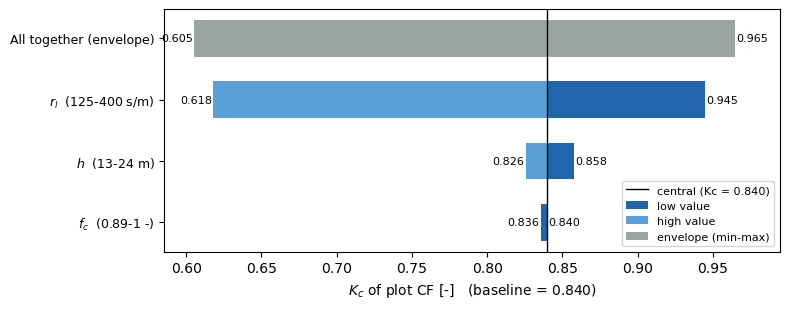

In [ ]:
import itertools

PARAMS_CF = {'rl': ('$r_l$', 's/m'), 'h': ('$h$', 'm'), 'fc': ('$f_c$', '-')}

def forest_with(**levels):
    '''FOREST with each given parameter set to 'lo', 'c' (central) or 'hi' in all strata.'''
    return {n: {**s, **{p: (s[p] if k == 'c' else s[f'{p}_{k}']) for p, k in levels.items()}}
            for n, s in FOREST.items()}

base_CF = Kc_CF_now
s0 = next(iter(FOREST.values()))   # ranges shown in the labels (first stratum)
rows = {}
for p, (sym, unit) in PARAMS_CF.items():
    rows[f"{sym}  ({s0[p + '_lo']:g}-{s0[p + '_hi']:g} {unit})"] = (Kc_CF_plot(forest_with(**{p: 'lo'})),
                                                                     Kc_CF_plot(forest_with(**{p: 'hi'})))
all_combos = [Kc_CF_plot(forest_with(**dict(zip(PARAMS_CF, ks))))
              for ks in itertools.product(['lo', 'c', 'hi'], repeat=len(PARAMS_CF))]
ENV = 'All together (envelope)'
rows[ENV] = (min(all_combos), max(all_combos))

sens_CF = pd.DataFrame(rows, index=['Kc (low value)', 'Kc (high value)']).T
sens_CF.loc[ENV] = [min(all_combos), max(all_combos)]
sens_CF['range'] = (sens_CF['Kc (low value)'] - sens_CF['Kc (high value)']).abs()
display(sens_CF.round(3))
print(f'Kc CF = {base_CF:.3f} (envelope {min(all_combos):.3f}-{max(all_combos):.3f})')

# tornado chart (envelope bar at the top), same style as the AF chart
order = list(sens_CF.index[:-1][np.argsort(sens_CF['range'].values[:-1])]) + [ENV]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(order) + 1.2))
C_LOW, C_HIGH, C_ENV = '#2166AC', '#5AA0D8', '#9AA5A0'
for i, name in enumerate(order):
    lo, hi = sens_CF.loc[name, ['Kc (low value)', 'Kc (high value)']]
    if name == ENV:
        ax.barh(i, hi - lo, left=lo, color=C_ENV, height=0.6, label='envelope (min-max)')
    else:
        ax.barh(i, lo - base_CF, left=base_CF, color=C_LOW,  height=0.6, label='low value'  if i == 0 else None)
        ax.barh(i, hi - base_CF, left=base_CF, color=C_HIGH, height=0.6, label='high value' if i == 0 else None)
    for v in (lo, hi):
        right = v >= base_CF
        ax.text(v + (0.001 if right else -0.001), i, f'{v:.3f}', va='center',
                ha='left' if right else 'right', fontsize=8)
ax.axvline(base_CF, color='black', lw=1, label=f'central (Kc = {base_CF:.3f})')
ax.set_yticks(range(len(order)), labels=order, fontsize=9)
ax.set_xlabel(f'$K_{{c}}$ of plot {PLOT_CF} [-]   (baseline = {base_CF:.3f})')
ax.legend(loc='lower right', fontsize=8)
xmin, xmax = sens_CF[['Kc (low value)', 'Kc (high value)']].values.min(), sens_CF[['Kc (low value)', 'Kc (high value)']].values.max()
ax.set_xlim(xmin - 0.02, xmax + 0.03)
plt.tight_layout()
fig.savefig(f'tornado_{PLOT_CF}.png', dpi=300, bbox_inches='tight')
plt.show()

### Save CF

In [ ]:
# ---- Save CF ----
sens_CF.to_csv(f'Kc_{PLOT_CF}_sensitivity.csv')
pd.Series({'Kc_now': Kc_CF_now, 'Kc_min_env': min(all_combos), 'Kc_max_env': max(all_combos)},
          name=PLOT_CF).to_csv(f'Kc_{PLOT_CF}.csv')     # the value for the ET calculation + envelope
print(f'Saved Kc_{PLOT_CF}.csv (Kc = {Kc_CF_now:.3f}) and Kc_{PLOT_CF}_sensitivity.csv')

Saved Kc_CF.csv (Kc = 0.840) and Kc_CF_sensitivity.csv
